In [1]:
import sys
print(sys.executable)

c:\Users\admin\Documents\Projects\transformer-uncertainity\venv\Scripts\python.exe


In [2]:
from datasets import load_dataset

In [3]:
dataset = load_dataset("stanfordnlp/imdb", cache_dir="../data/imdb")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [4]:
# Actual Reviews
for i in [0, 100, 500, 1000, 5000]:
    print(f"\n--- Example {i} (label={dataset['train'][i]['label']}) ---")
    print(dataset['train'][i]['text'])


--- Example 0 (label=0) ---
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes

In [5]:
import pandas as pd

train_labels = dataset['train']['label']
print(f"Positive (1): {train_labels.count(1)}")
print(f"Negative (0): {train_labels.count(0)}")

Positive (1): 12500
Negative (0): 12500


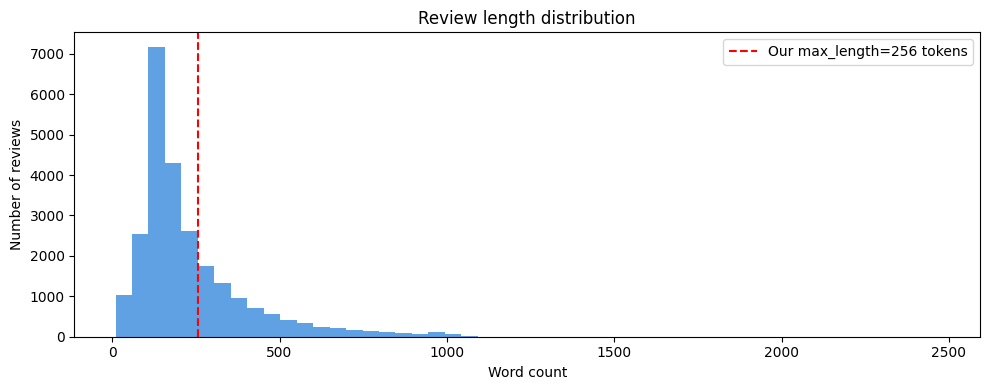


Mean length: 234 words
Max length: 2470 words
% reviews under 230 words for 256 tokens: 65.5%
% reviews under 490 words for 512 tokens: 91.5%


In [6]:
import matplotlib.pyplot as plt

lengths = [len(r.split()) for r in dataset['train']['text']]
plt.figure(figsize=(10, 4))
plt.hist(lengths, bins=50, color='#378ADD', alpha=0.8)
plt.axvline(256, color='red', linestyle='--', label='Our max_length=256 tokens')
plt.xlabel('Word count')
plt.ylabel('Number of reviews')
plt.title('Review length distribution')
plt.legend()
plt.tight_layout()
#plt.savefig('../results/figures/review_lengths.png', dpi=150)
plt.show()
print(f"\nMean length: {sum(lengths)/len(lengths):.0f} words")
print(f"Max length: {max(lengths)} words")
print(f"% reviews under 230 words for 256 tokens: {sum(1 for l in lengths if l <230)/len(lengths)*100:.1f}%")
print(f"% reviews under 490 words for 512 tokens: {sum(1 for l in lengths if l <490)/len(lengths)*100:.1f}%")

In [7]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

True
NVIDIA GeForce GTX 1650
VRAM: 4.3 GB
